In [1]:
import os
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split


# ============================================================
# CONFIGURATION
# ============================================================

IMAGE_SIZE = (260, 260)
BATCH_SIZE = 32

MAX_SAMPLES = 3000

TEST_SIZE = 0.20
RANDOM_STATE = 42


# ============================================================
# HARD-CODE YOUR DATASET PATHS
# ============================================================

healthy_path = r"/kaggle/input/datasets/amrutdesh/unified/Unified_Data/Healthy"

unhealthy_path = r"/kaggle/input/datasets/amrutdesh/unified/Unified_Data/Unhealthy"


# ============================================================
# FUNCTION 1: LOAD IMAGE PATHS AND SPLIT DATA
# ============================================================

def load_data(
    healthy_path,
    unhealthy_path,
    max_samples=None,
    test_size=0.2,
    random_state=42
):

    image_paths = []
    labels = []

    # --------------------------------------------------------
    # Healthy images
    # --------------------------------------------------------

    healthy_files = [
        os.path.join(healthy_path, file)
        for file in os.listdir(healthy_path)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
        )
    ]

    rng = np.random.default_rng(random_state)
    rng.shuffle(healthy_files)

    if max_samples is not None:
        healthy_files = healthy_files[:max_samples]

    image_paths.extend(healthy_files)
    labels.extend([0] * len(healthy_files))


    # --------------------------------------------------------
    # Unhealthy images
    # --------------------------------------------------------

    unhealthy_files = [
        os.path.join(unhealthy_path, file)
        for file in os.listdir(unhealthy_path)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
        )
    ]

    rng.shuffle(unhealthy_files)

    if max_samples is not None:
        unhealthy_files = unhealthy_files[:max_samples]

    image_paths.extend(unhealthy_files)
    labels.extend([1] * len(unhealthy_files))


    # --------------------------------------------------------
    # Convert to NumPy arrays
    # --------------------------------------------------------

    image_paths = np.array(image_paths)
    labels = np.array(labels)


    # --------------------------------------------------------
    # Dataset information
    # --------------------------------------------------------

    print("==========================================")
    print("DATASET INFORMATION")
    print("==========================================")

    print(f"Total images : {len(image_paths)}")
    print(f"Healthy      : {np.sum(labels == 0)}")
    print(f"Unhealthy    : {np.sum(labels == 1)}")


    # --------------------------------------------------------
    # Train / Test split
    # --------------------------------------------------------

    X_train, X_test, y_train, y_test = train_test_split(
        image_paths,
        labels,
        test_size=test_size,
        random_state=random_state,
        stratify=labels
    )


    print("\n==========================================")
    print("DATA SPLIT")
    print("==========================================")

    print(f"Training images : {len(X_train)}")
    print(f"Testing images  : {len(X_test)}")


    return X_train, X_test, y_train, y_test


# ============================================================
# FUNCTION 2: CREATE TF.DATA DATASET
# ============================================================

def create_dataset(
    image_paths,
    labels,
    image_size=(260, 260),
    batch_size=32,
    shuffle=False
):

    def load_image(path, label):

        # Read image from disk
        image = tf.io.read_file(path)

        # Decode image
        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        # Ensure TensorFlow knows the image shape
        image.set_shape([None, None, 3])

        # ----------------------------------------------------
        # Resize 224 × 224 → 260 × 260
        # ----------------------------------------------------

        image = tf.image.resize(
            image,
            image_size
        )

        # Convert to float32
        image = tf.cast(
            image,
            tf.float32
        )

        return image, label


    # Create dataset from paths
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )


    # Shuffle only training dataset
    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            reshuffle_each_iteration=True
        )


    # Load images when required
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )


    # Create batches
    dataset = dataset.batch(
        batch_size
    )


    # Prefetch next batch while model trains
    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )


    return dataset


# ============================================================
# RUN STAGE 1
# ============================================================

X_train, X_test, y_train, y_test = load_data(
    healthy_path=healthy_path,
    unhealthy_path=unhealthy_path,
    max_samples=MAX_SAMPLES,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)


# ============================================================
# CREATE TRAINING DATASET
# ============================================================

train_dataset = create_dataset(
    X_train,
    y_train,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)


# ============================================================
# CREATE TEST DATASET
# ============================================================

test_dataset = create_dataset(
    X_test,
    y_test,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("\n==========================================")
print("DATA PIPELINE READY")
print("==========================================")

print("Image size :", IMAGE_SIZE)
print("Batch size :", BATCH_SIZE)

DATASET INFORMATION
Total images : 6000
Healthy      : 3000
Unhealthy    : 3000

DATA SPLIT
Training images : 4800
Testing images  : 1200

DATA PIPELINE READY
Image size : (260, 260)
Batch size : 32


I0000 00:00:1787071707.517931      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787071707.520911      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB2


def build_efficientnet_b2_stage1(
    input_shape=(260, 260, 3),
    dropout_rate=0.3,
    learning_rate=1e-3
):
    """
    Stage 1:
    EfficientNetB2 is used as a frozen feature extractor.

    Only the classification head is trainable.

    Classes:
        0 -> Healthy
        1 -> Unhealthy
    """

    # ========================================================
    # PRETRAINED EFFICIENTNETB2
    # ========================================================

    base_model = EfficientNetB2(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )


    # ========================================================
    # FREEZE ENTIRE EFFICIENTNET
    # ========================================================

    base_model.trainable = False


    # ========================================================
    # CLASSIFICATION HEAD
    # ========================================================

    inputs = layers.Input(
        shape=input_shape
    )

    # Extract features
    x = base_model(
        inputs,
        training=False
    )

    # Convert feature maps into feature vector
    x = layers.GlobalAveragePooling2D()(x)

    # Prevent overfitting
    x = layers.Dropout(
        dropout_rate
    )(x)

    # Binary classification
    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)


    # ========================================================
    # COMPLETE MODEL
    # ========================================================

    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )


    return model

In [3]:
model = build_efficientnet_b2_stage1(
    input_shape=(260, 260, 3),
    dropout_rate=0.3,
    learning_rate=1e-3
)

model.summary()

print("Total parameters     :", model.count_params())
print("Trainable parameters :", 
      np.sum([
          tf.keras.backend.count_params(w)
          for w in model.trainable_weights
      ]))

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb2 (Functional)     │ (None, 9, 9, 1408)     │     7,768,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1408)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,409 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,769,978 (29.64 MB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 7,768,569 (29.63 MB)

Total parameters     : 7769978
Trainable parameters : 1409


In [4]:
history_stage1 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10
)

Epoch 1/10


2026-08-18 16:49:00.110527: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:00.259802: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:00.638564: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:00.784008: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:01.644818: E external/local_xla/xla/stream_

150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.7163 - loss: 0.5672

2026-08-18 16:49:43.273563: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:43.415748: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:43.749834: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:43.894543: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:49:44.747500: E external/local_xla/xla/stream_

150/150 ━━━━━━━━━━━━━━━━━━━━ 80s 246ms/step - accuracy: 0.7869 - loss: 0.4895 - val_accuracy: 0.8583 - val_loss: 0.3830
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.8575 - loss: 0.3580 - val_accuracy: 0.8842 - val_loss: 0.3184
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - accuracy: 0.8719 - loss: 0.3231 - val_accuracy: 0.8867 - val_loss: 0.2913
Epoch 4/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - accuracy: 0.8771 - loss: 0.3034 - val_accuracy: 0.8958 - val_loss: 0.2743
Epoch 5/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 14s 94ms/step - accuracy: 0.8835 - loss: 0.2907 - val_accuracy: 0.8917 - val_loss: 0.2638
Epoch 6/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 15s 99ms/step - accuracy: 0.8848 - loss: 0.2806 - val_accuracy: 0.8942 - val_loss: 0.2545
Epoch 7/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 15s 101ms/step - accuracy: 0.8904 - loss: 0.2656 - val_accuracy: 0.9017 - val_loss: 0.2493
Epoch 8/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 14s 95ms/step - accuracy: 0.8896 - loss: 0.2658 - val_accur

In [5]:
model.save_weights("efficientnet2500_b2_stage1.weights.h5")

In [6]:
# ============================================================
# STAGE 2: PARTIAL FINE-TUNING
# ============================================================

# Find the EfficientNetB2 base model
base_model = None

for layer in model.layers:

    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break


print("Base model:", base_model.name)

Base model: efficientnetb2


In [7]:
# ============================================================
# UNFREEZE LAST 30 LAYERS
# ============================================================

FINE_TUNE_LAYERS = 30

# First make the whole backbone trainable
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:

    layer.trainable = False


# Keep Batch Normalization layers frozen
for layer in base_model.layers[-FINE_TUNE_LAYERS:]:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

In [8]:
total_params = model.count_params()

trainable_params = np.sum([
    tf.keras.backend.count_params(weight)
    for weight in model.trainable_weights
])

non_trainable_params = (
    total_params - trainable_params
)

print("\n======================================")
print("FINE-TUNING CONFIGURATION")
print("======================================")

print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")
print(f"Non-trainable params  : {non_trainable_params:,}")
print(f"Fine-tuning layers    : {FINE_TUNE_LAYERS}")


FINE-TUNING CONFIGURATION
Total parameters      : 7,769,978
Trainable parameters  : 2,958,413
Non-trainable params  : 4,811,565
Fine-tuning layers    : 30


In [9]:
# ============================================================
# RECOMPILE FOR FINE-TUNING
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [10]:
# ============================================================
# TRAIN STAGE 2
# ============================================================

history_stage2 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=40
)

Epoch 1/40


2026-08-18 16:52:20.043475: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:52:20.187501: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:52:21.019175: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:52:21.156860: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-18 16:52:21.437566: E external/local_xla/xla/stream_

150/150 ━━━━━━━━━━━━━━━━━━━━ 69s 217ms/step - accuracy: 0.8933 - loss: 0.2536 - val_accuracy: 0.9083 - val_loss: 0.2183
Epoch 2/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 18s 119ms/step - accuracy: 0.9019 - loss: 0.2358 - val_accuracy: 0.9108 - val_loss: 0.2087
Epoch 3/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 17s 116ms/step - accuracy: 0.9044 - loss: 0.2202 - val_accuracy: 0.9133 - val_loss: 0.1976
Epoch 4/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - accuracy: 0.9115 - loss: 0.2183 - val_accuracy: 0.9133 - val_loss: 0.1932
Epoch 5/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 16s 105ms/step - accuracy: 0.9160 - loss: 0.2113 - val_accuracy: 0.9125 - val_loss: 0.1904
Epoch 6/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 16s 107ms/step - accuracy: 0.9140 - loss: 0.2038 - val_accuracy: 0.9225 - val_loss: 0.1800
Epoch 7/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 17s 111ms/step - accuracy: 0.9177 - loss: 0.1977 - val_accuracy: 0.9267 - val_loss: 0.1729
Epoch 8/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - accuracy: 0.9237 - loss: 0.1878 - val

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [12]:
def evaluate_stage(
    model,
    dataset,
    y_true,
    stage_name
):
    """
    Evaluates one training stage.

    Returns:
        Dictionary containing all major metrics.
    """

    # ========================================================
    # MODEL LOSS AND ACCURACY
    # ========================================================

    loss, accuracy = model.evaluate(
        dataset,
        verbose=0
    )


    # ========================================================
    # PREDICTIONS
    # ========================================================

    probabilities = model.predict(
        dataset,
        verbose=0
    ).flatten()

    y_pred = (
        probabilities >= 0.5
    ).astype(int)


    # ========================================================
    # METRICS
    # ========================================================

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )


    # ========================================================
    # CLASSIFICATION REPORT
    # ========================================================

    print("\n")
    print("=" * 60)
    print(stage_name)
    print("=" * 60)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=[
                "Healthy",
                "Unhealthy"
            ],
            digits=4,
            zero_division=0
        )
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(
        figsize=(6, 5)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "Healthy",
            "Unhealthy"
        ],
        yticklabels=[
            "Healthy",
            "Unhealthy"
        ]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(
        f"{stage_name} - Confusion Matrix"
    )

    plt.show()


    return {
        "stage": stage_name,
        "loss": loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "y_pred": y_pred,
        "probabilities": probabilities,
        "confusion_matrix": cm
    }

In [13]:
stage1_model = build_efficientnet_b2_stage1(
    input_shape=(260, 260, 3),
    dropout_rate=0.3,
    learning_rate=1e-3
)

In [14]:
stage1_model.load_weights(
    "efficientnet2500_b2_stage1.weights.h5"
)

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))




Stage 1 - Feature Extraction
Accuracy  : 0.9000
Precision : 0.9240
Recall    : 0.8717
F1-score  : 0.8971

Classification Report:

              precision    recall  f1-score   support

     Healthy     0.8785    0.9283    0.9028       600
   Unhealthy     0.9240    0.8717    0.8971       600

    accuracy                         0.9000      1200
   macro avg     0.9013    0.9000    0.8999      1200
weighted avg     0.9013    0.9000    0.8999      1200



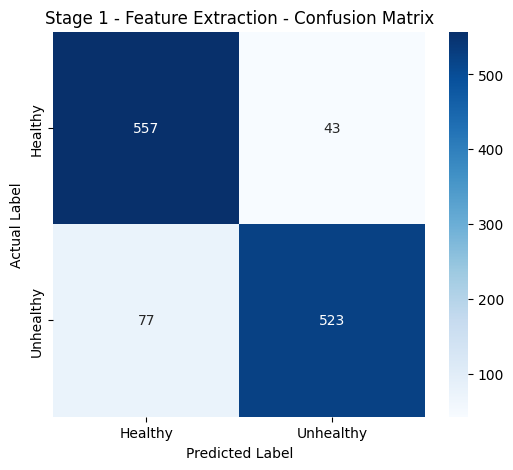

In [15]:
stage1_results = evaluate_stage(
    model=stage1_model,
    dataset=test_dataset,
    y_true=y_test,
    stage_name="Stage 1 - Feature Extraction"
)



Stage 2 - Partial Fine-Tuning
Accuracy  : 0.9533
Precision : 0.9533
Recall    : 0.9533
F1-score  : 0.9533

Classification Report:

              precision    recall  f1-score   support

     Healthy     0.9533    0.9533    0.9533       600
   Unhealthy     0.9533    0.9533    0.9533       600

    accuracy                         0.9533      1200
   macro avg     0.9533    0.9533    0.9533      1200
weighted avg     0.9533    0.9533    0.9533      1200



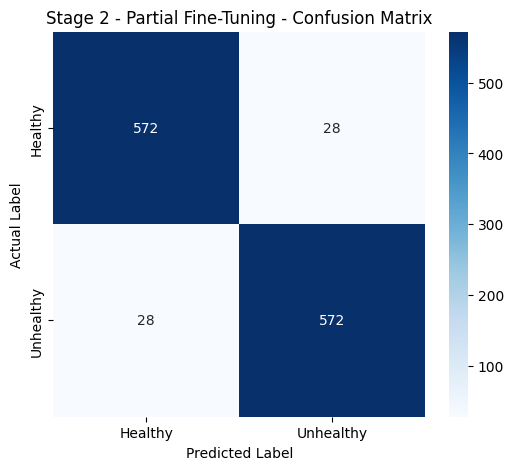

In [16]:
stage2_results = evaluate_stage(
    model=model,
    dataset=test_dataset,
    y_true=y_test,
    stage_name="Stage 2 - Partial Fine-Tuning"
)

In [17]:
comparison = pd.DataFrame({

    "Stage": [
        "Stage 1 - Feature Extraction",
        "Stage 2 - Partial Fine-Tuning"
    ],

    "Accuracy": [
        stage1_results["accuracy"],
        stage2_results["accuracy"]
    ],

    "Precision": [
        stage1_results["precision"],
        stage2_results["precision"]
    ],

    "Recall": [
        stage1_results["recall"],
        stage2_results["recall"]
    ],

    "F1-Score": [
        stage1_results["f1_score"],
        stage2_results["f1_score"]
    ]

})


print("\n==============================================")
print("UNIFIED MODEL COMPARISON")
print("==============================================")

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


UNIFIED MODEL COMPARISON
                        Stage  Accuracy  Precision  Recall  F1-Score
 Stage 1 - Feature Extraction    0.9000     0.9240  0.8717    0.8971
Stage 2 - Partial Fine-Tuning    0.9533     0.9533  0.9533    0.9533


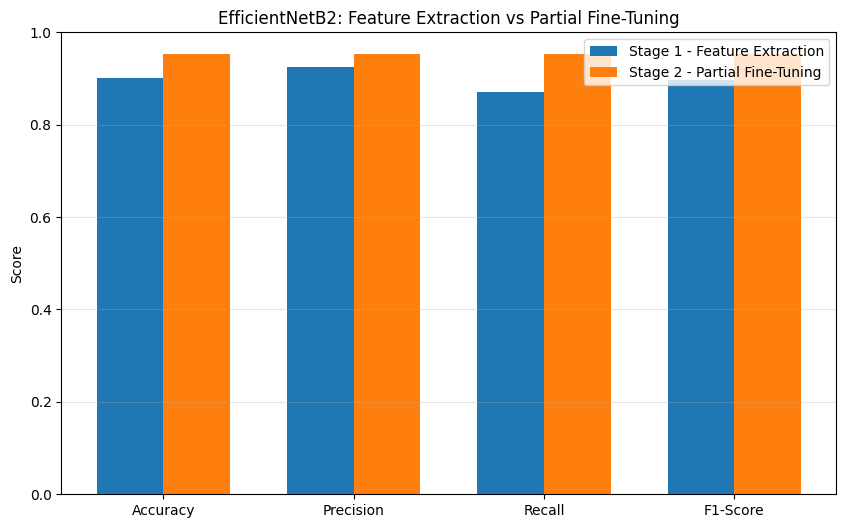

In [18]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

stage1_values = [
    stage1_results["accuracy"],
    stage1_results["precision"],
    stage1_results["recall"],
    stage1_results["f1_score"]
]

stage2_values = [
    stage2_results["accuracy"],
    stage2_results["precision"],
    stage2_results["recall"],
    stage2_results["f1_score"]
]


x = np.arange(len(metrics))
width = 0.35


plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    stage1_values,
    width,
    label="Stage 1 - Feature Extraction"
)

plt.bar(
    x + width / 2,
    stage2_values,
    width,
    label="Stage 2 - Partial Fine-Tuning"
)


plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "EfficientNetB2: Feature Extraction vs Partial Fine-Tuning"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

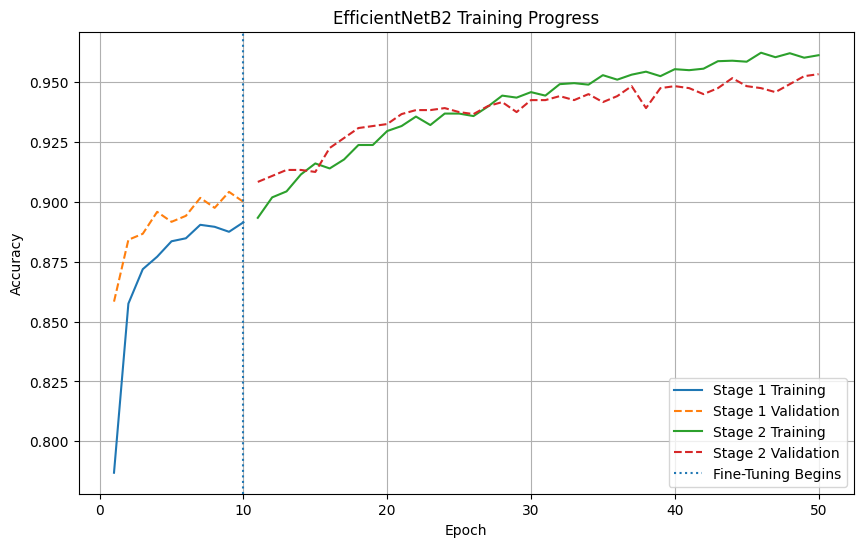

In [19]:
stage1_epochs = range(
    1,
    len(history_stage1.history["accuracy"]) + 1
)

stage2_epochs = range(
    len(history_stage1.history["accuracy"]) + 1,
    len(history_stage1.history["accuracy"])
    + len(history_stage2.history["accuracy"])
    + 1
)


plt.figure(figsize=(10, 6))


# Stage 1 training
plt.plot(
    stage1_epochs,
    history_stage1.history["accuracy"],
    label="Stage 1 Training"
)


# Stage 1 validation
plt.plot(
    stage1_epochs,
    history_stage1.history["val_accuracy"],
    linestyle="--",
    label="Stage 1 Validation"
)


# Stage 2 training
plt.plot(
    stage2_epochs,
    history_stage2.history["accuracy"],
    label="Stage 2 Training"
)


# Stage 2 validation
plt.plot(
    stage2_epochs,
    history_stage2.history["val_accuracy"],
    linestyle="--",
    label="Stage 2 Validation"
)


# Mark transition between stages
plt.axvline(
    x=len(history_stage1.history["accuracy"]),
    linestyle=":",
    label="Fine-Tuning Begins"
)


plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "EfficientNetB2 Training Progress"
)

plt.legend()

plt.grid(True)

plt.show()

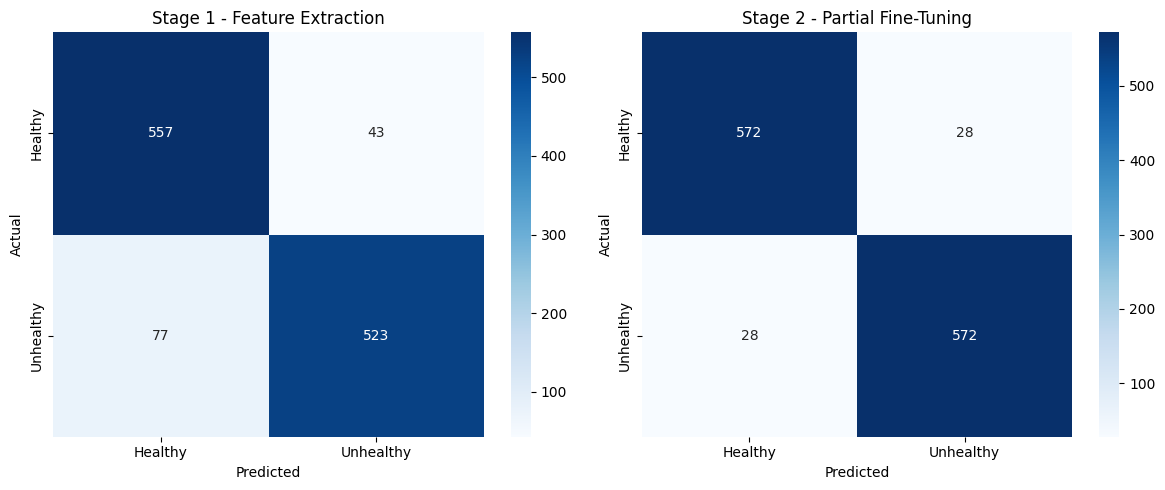

In [20]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# ------------------------------------------------------------
# Stage 1
# ------------------------------------------------------------

sns.heatmap(
    stage1_results["confusion_matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Unhealthy"],
    yticklabels=["Healthy", "Unhealthy"],
    ax=axes[0]
)

axes[0].set_title(
    "Stage 1 - Feature Extraction"
)

axes[0].set_xlabel(
    "Predicted"
)

axes[0].set_ylabel(
    "Actual"
)


# ------------------------------------------------------------
# Stage 2
# ------------------------------------------------------------

sns.heatmap(
    stage2_results["confusion_matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Unhealthy"],
    yticklabels=["Healthy", "Unhealthy"],
    ax=axes[1]
)

axes[1].set_title(
    "Stage 2 - Partial Fine-Tuning"
)

axes[1].set_xlabel(
    "Predicted"
)

axes[1].set_ylabel(
    "Actual"
)


plt.tight_layout()

plt.show()